# Business Sales Performance Analytics
**Future Interns · Data Science & Analytics · Task 1**

## Objective
Analyse a year of online-retail transactions to answer four business questions:

1. **Revenue trends** – how does revenue move over time, and when are the peaks?
2. **Top-selling products** – which products really drive the business?
3. **High-value categories** – which product groups earn the most?
4. **Regional performance** – which countries matter, and where is the headroom?

## Dataset
*Online Retail Dataset* (Kaggle, `ulrikthygepedersen/online-retail-dataset`): ~542k line items from a UK-based, non-store online retailer, **1 Dec 2010 – 9 Dec 2011**. Columns: `InvoiceNo, StockCode, Description, Quantity, InvoiceDate, UnitPrice, CustomerID, Country`.

## Approach
Load → audit data quality → clean (with row accounting) → define KPIs → analyse trends, products, categories, regions, customers and returns → turn the results into recommendations.

**Tools:** Python (pandas, matplotlib, seaborn).

In [1]:
import warnings; warnings.filterwarnings("ignore")
import re, json, textwrap
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
from IPython.display import Markdown, display

# ---- Display + plotting defaults -------------------------------------------------
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

NAVY, TEAL, AMBER, RED, GREY = "#1F3A5F", "#2A9D8F", "#E9A23B", "#D1495B", "#8D99AE"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": .25, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 13, "font.size": 10,
})

IMG, OUT = Path("../images"), Path("../outputs")
IMG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

gbp_k = FuncFormatter(lambda x, pos=None: f"£{x/1e3:,.0f}k")      # axis formatter
def gbp(x):                                                          # text formatter
    return f"£{x/1e6:,.2f}M" if abs(x) >= 1e6 else f"£{x/1e3:,.0f}k"
def save(fig, name):
    fig.savefig(IMG / name, dpi=150, bbox_inches="tight", facecolor="white")
def short(s, n=34):
    return textwrap.shorten(str(s).title(), n, placeholder="…")

M = {}   # collects headline metrics; saved to outputs/kpis.json at the end

## 1. Load the data

In [2]:
raw = pd.read_csv("../data/online_retail.csv")
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"])
print(f"Rows: {len(raw):,}  |  Columns: {raw.shape[1]}")
print(f"Period: {raw.InvoiceDate.min():%d %b %Y} -> {raw.InvoiceDate.max():%d %b %Y}")
raw.head()

Rows: 541,909  |  Columns: 8
Period: 01 Dec 2010 -> 09 Dec 2011

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 2. Data-quality audit
Before any analysis, check what is wrong with the data. Issues can overlap, so the counts below are *not* additive.

In [3]:
inv = raw.InvoiceNo.astype(str)
is_cancel = inv.str.startswith("C")
stock = raw.StockCode.astype(str).str.strip()

audit = pd.Series({
    "Total rows": len(raw),
    "Exact duplicate rows": raw.duplicated().sum(),
    "Cancellation lines (InvoiceNo starts with 'C')": is_cancel.sum(),
    "Non-cancel lines with Quantity <= 0 (stock adjustments)": ((raw.Quantity <= 0) & ~is_cancel).sum(),
    "Lines with UnitPrice <= 0": (raw.UnitPrice <= 0).sum(),
    "Missing CustomerID": raw.CustomerID.isna().sum(),
    "Missing Description": raw.Description.isna().sum(),
    "Non-product StockCodes (POST, DOT, M, BANK CHARGES, AMAZONFEE...)": (~stock.str.match(r"^\d{5}")).sum(),
}, name="rows")
audit.to_frame().assign(pct_of_rows=lambda d: d.rows / len(raw) * 100)

,rows,pct_of_rows
Total rows,541909,100.00
Exact duplicate rows,5268,0.97
Cancellation lines (InvoiceNo starts with 'C'),9288,1.71
Non-cancel lines with Quantity <= 0 (stock adjustments),1336,0.25
Lines with UnitPrice <= 0,2517,0.46
Missing CustomerID,135080,24.93
Missing Description,1454,0.27
"Non-product StockCodes (POST, DOT, M, BANK CHARGES, AMAZONFEE...)",2995,0.55


### What this means
* **Duplicates** are removed – the same line appearing twice would double-count revenue.
* **Cancellations** (`C…` invoices) are *returns/cancelled orders*. They must not be mixed into sales, but they are real money going back, so I track them separately and report **net revenue = sales − returns**.
* **Quantity ≤ 0 with price 0** rows are stock write-offs ("damaged", "lost") – not sales.
* **Non-product codes** (postage, manual adjustments, bank charges, Amazon fees) are operating items, not products, so they are excluded from product/category analysis.
* **Missing CustomerID (~25% of lines)** is kept for revenue analysis (it is still revenue) but excluded from customer-level analysis.

## 3. Cleaning (with row accounting)
Every step reports how many rows it touches, so the cleaning is auditable.

In [4]:
df = raw.drop_duplicates().copy()
df["InvoiceNo"] = df.InvoiceNo.astype(str)
df["StockCode"] = df.StockCode.astype(str).str.strip()
df["IsCancel"] = df.InvoiceNo.str.startswith("C")
steps = [("Raw rows", len(raw)), ("After removing exact duplicates", len(df))]

df = df[df.StockCode.str.match(r"^\d{5}")]                       # real products only
steps.append(("After removing non-product lines (postage, fees, manual...)", len(df)))

sales   = df[~df.IsCancel & (df.Quantity > 0) & (df.UnitPrice > 0)].copy()
returns = df[ df.IsCancel & (df.Quantity < 0) & (df.UnitPrice > 0)].copy()
dropped = len(df) - len(sales) - len(returns)
steps += [("  of which: valid sales lines", len(sales)),
          ("  of which: valid return lines", len(returns)),
          ("  of which: zero-price / adjustment lines dropped", dropped)]

# One clean description per StockCode (650 codes carry several spellings)
desc_map = (df.dropna(subset=["Description"])
              .assign(D=lambda x: x.Description.str.strip().str.upper())
              .groupby("StockCode")["D"].agg(lambda s: s.value_counts().index[0]))
for t in (sales, returns):
    t["Description"] = t.StockCode.map(desc_map).fillna("UNKNOWN")
    t["Revenue"] = t.Quantity * t.UnitPrice                       # negative for returns
    t["Month"] = t.InvoiceDate.dt.to_period("M").dt.to_timestamp()

pd.DataFrame(steps, columns=["Step", "Rows"]).set_index("Step")

,Rows
Step,
Raw rows,541909
After removing exact duplicates,536641
"After removing non-product lines (postage, fees, manual...)",533652
of which: valid sales lines,522504
of which: valid return lines,8668
of which: zero-price / adjustment lines dropped,2480


## 4. Headline KPIs
**Definitions** – *Gross revenue* = value of valid sales lines. *Returns* = value of cancelled lines. *Net revenue* = gross − returns. *AOV* = gross revenue per invoice.

In [5]:
gross   = sales.Revenue.sum()
ret     = -returns.Revenue.sum()
net     = gross - ret
order_v = sales.groupby("InvoiceNo").Revenue.sum()
n_orders, n_cust = sales.InvoiceNo.nunique(), sales.CustomerID.nunique()
unid_share = sales.loc[sales.CustomerID.isna(), "Revenue"].sum() / gross

M.update(gross=gross, returns=ret, net=net, return_rate=ret / gross, orders=n_orders,
         customers=n_cust, aov_mean=order_v.mean(), aov_median=order_v.median(),
         units=int(sales.Quantity.sum()), skus=sales.StockCode.nunique(),
         unidentified_rev_share=unid_share)

kpi = pd.Series({
    "Gross revenue": f"£{gross:,.0f}",
    "Returns / cancellations": f"£{ret:,.0f}  ({ret/gross:.1%} of gross)",
    "Net revenue": f"£{net:,.0f}",
    "Orders (invoices)": f"{n_orders:,}",
    "Identified customers": f"{n_cust:,}",
    "Average order value (mean)": f"£{order_v.mean():,.0f}",
    "Median order value": f"£{order_v.median():,.0f}",
    "Units sold": f"{int(sales.Quantity.sum()):,}",
    "Active products (SKUs)": f"{sales.StockCode.nunique():,}",
    "Revenue from customers with no ID": f"{unid_share:.1%}",
}, name="value")
kpi.to_frame()

,value
Gross revenue,"£10,246,821"
Returns / cancellations,"£475,901 (4.6% of gross)"
Net revenue,"£9,770,920"
Orders (invoices),"19,773"
Identified customers,"4,334"
Average order value (mean),£518
Median order value,£302
Units sold,"5,561,280"
Active products (SKUs),"3,900"
Revenue from customers with no ID,14.7%


### ⚠️ Outlier check – two "phantom" orders
The mean order value (≈£518) is far above the median (≈£302), which signals extreme orders. Let me look at the biggest orders and biggest returns.

In [6]:
cols = ["InvoiceNo", "Description", "Quantity", "UnitPrice", "InvoiceDate", "CustomerID", "Revenue"]
display(Markdown("**Largest sales lines**"))
display(sales.nlargest(4, "Revenue")[cols])
display(Markdown("**Largest return lines**"))
display(returns.nsmallest(4, "Revenue")[cols])

**Largest sales lines**

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,Revenue
540421,581483,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,2011-12-09 09:15:00,"16,446.00","168,469.60"
61619,541431,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,2011-01-18 10:01:00,"12,346.00","77,183.60"
222680,556444,PICNIC BASKET WICKER SMALL,60,649.50,2011-06-10 15:28:00,"15,098.00","38,970.00"
348325,567423,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,2011-09-20 11:05:00,"17,450.00","7,144.72"


**Largest return lines**

,InvoiceNo,Description,Quantity,UnitPrice,InvoiceDate,CustomerID,Revenue
540422,C581484,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,2011-12-09 09:27:00,"16,446.00","-168,469.60"
61624,C541433,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,2011-01-18 10:17:00,"12,346.00","-77,183.60"
160145,C550456,FAIRY CAKE FLANNEL ASSORTED COLOUR,-3114,2.10,2011-04-18 13:08:00,"15,749.00","-6,539.40"
160143,C550456,WHITE HANGING HEART T-LIGHT HOLDER,-1930,2.55,2011-04-18 13:08:00,"15,749.00","-4,921.50"


Two single-line orders – **80,995 × PAPER CRAFT, LITTLE BIRDIE (£168,470, 9 Dec 2011)** and **74,215 × MEDIUM CERAMIC TOP STORAGE JAR (£77,184, 18 Jan 2011)** – were **cancelled minutes after being placed** by the same customers. Together they inflate *gross* revenue by ~£246k (~2.4%) and would make these two products look like best-sellers.

**Decision:** keep them in the data (they are genuine records) and base all headline revenue conclusions on **net revenue**, where each order and its cancellation offset each other. For **return-rate** analysis I additionally build an *underlying* view that removes these two order/cancellation pairs, otherwise they masquerade as a return problem (e.g. December 2011 would show a 28% return rate purely because of one cancelled order).

In [7]:
# "Underlying" view: drop the two mega-orders (>= 50,000 units) and their cancellations
mega_s = sales[sales.Quantity >= 50_000]
mega_r = returns[returns.Quantity <= -50_000]
sales_adj, returns_adj = sales.drop(mega_s.index), returns.drop(mega_r.index)

rr_reported   = -returns.Revenue.sum() / sales.Revenue.sum()
rr_underlying = -returns_adj.Revenue.sum() / sales_adj.Revenue.sum()
M.update(return_rate_underlying=rr_underlying, phantom_value=mega_s.Revenue.sum(),
         phantom_share=mega_s.Revenue.sum() / sales.Revenue.sum())
print(f"Mega-orders removed: {len(mega_s)} sales lines / {len(mega_r)} cancellation lines, worth £{mega_s.Revenue.sum():,.0f} gross")
print(f"Return rate as recorded: {rr_reported:.1%}   |   underlying (ex mega-orders): {rr_underlying:.1%}")

Mega-orders removed: 2 sales lines / 2 cancellation lines, worth £245,653 gross
Return rate as recorded: 4.6%   |   underlying (ex mega-orders): 2.3%

## 5. Revenue trends

In [8]:
monthly = pd.DataFrame({
    "gross":   sales.groupby("Month").Revenue.sum(),
    "returns": -returns.groupby("Month").Revenue.sum(),
    "orders":  sales.groupby("Month").InvoiceNo.nunique(),
}).fillna(0)
monthly["net"] = monthly.gross - monthly.returns
monthly["mom_growth_%"] = monthly.net.pct_change() * 100
monthly.index = monthly.index.strftime("%b %Y")
monthly.to_csv(OUT / "monthly_revenue.csv")
monthly

,gross,returns,orders,net,mom_growth_%
Month,,,,,
Dec 2010,"775,572.23","17,547.86",1550,"758,024.37",NaN
Jan 2011,"670,361.99","91,525.05",1081,"578,836.94",-23.64
Feb 2011,"507,783.42","8,335.52",1093,"499,447.90",-13.72
Mar 2011,"689,708.49","10,504.30",1440,"679,204.19",35.99
Apr 2011,"515,354.78","33,316.06",1235,"482,038.72",-29.03
May 2011,"739,914.35","8,948.23",1668,"730,966.12",51.64
Jun 2011,"737,558.98","13,713.84",1525,"723,845.14",-0.97
Jul 2011,"688,144.79","11,407.26",1452,"676,737.53",-6.51
Aug 2011,"724,196.76","22,926.57",1339,"701,270.19",3.63


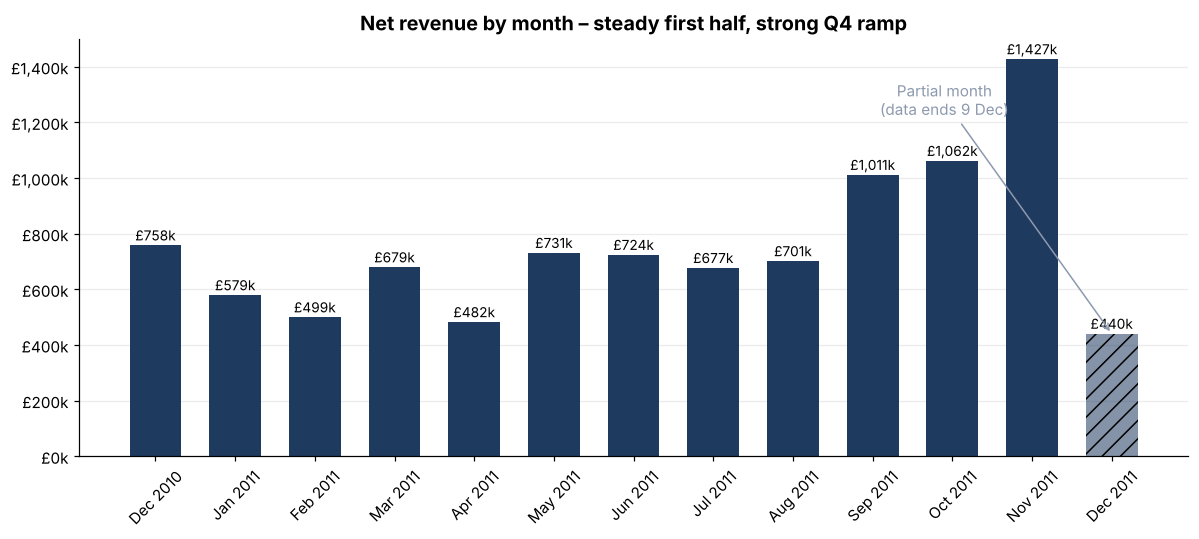

In [9]:
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.bar(monthly.index, monthly.net, color=NAVY, width=.65)
bars[-1].set_hatch("//"); bars[-1].set_alpha(.55)                  # Dec 2011 is a partial month
for b, v in zip(bars, monthly.net):
    ax.text(b.get_x() + b.get_width() / 2, v + 18000, f"£{v/1e3:,.0f}k", ha="center", fontsize=9)
ax.annotate("Partial month\n(data ends 9 Dec)", xy=(len(monthly) - 1, monthly.net.iloc[-1]),
            xytext=(len(monthly) - 3.1, monthly.net.max() * .86), ha="center",
            arrowprops=dict(arrowstyle="->", color=GREY), color=GREY)
ax.yaxis.set_major_formatter(gbp_k); ax.grid(axis="x", visible=False)
ax.set_title("Net revenue by month – steady first half, strong Q4 ramp")
plt.xticks(rotation=45); fig.tight_layout(); save(fig, "01_monthly_revenue.png")

In [10]:
full = monthly.iloc[1:-1]                      # Jan-Nov 2011 = 11 clean months (Dec 2010 is also full, Dec 2011 partial)
jan_nov = monthly.loc["Jan 2011":"Nov 2011", "net"]
q4_share  = jan_nov.loc[["Sep 2011", "Oct 2011", "Nov 2011"]].sum() / jan_nov.sum()
h1_avg    = jan_nov.loc["Jan 2011":"Aug 2011"].mean()
nov_vs_h1 = jan_nov["Nov 2011"] / h1_avg

# Like-for-like: first 9 days of December in both years, on NET revenue
def net_window(a, b):
    s = sales[(sales.InvoiceDate >= a) & (sales.InvoiceDate < b)].Revenue.sum()
    r = returns[(returns.InvoiceDate >= a) & (returns.InvoiceDate < b)].Revenue.sum()
    return s + r
d10, d11 = net_window("2010-12-01", "2010-12-10"), net_window("2011-12-01", "2011-12-10")
M.update(q4_share=q4_share, nov_vs_h1=nov_vs_h1, dec9_2010=d10, dec9_2011=d11, dec9_growth=d11 / d10 - 1,
         best_month=jan_nov.idxmax(), best_month_net=jan_nov.max())

print(f"Sep-Nov 2011 = {q4_share:.1%} of Jan-Nov 2011 net revenue (an even spread would be 27.3%)")
print(f"Nov 2011 net revenue is {nov_vs_h1:.2f}x the Jan-Aug 2011 monthly average")
print(f"Like-for-like, 1-9 Dec net revenue: 2010 £{d10:,.0f} -> 2011 £{d11:,.0f}  ({d11/d10-1:+.1%})")

Sep-Nov 2011 = 40.8% of Jan-Nov 2011 net revenue (an even spread would be 27.3%)
Nov 2011 net revenue is 2.25x the Jan-Aug 2011 monthly average
Like-for-like, 1-9 Dec net revenue: 2010 £401,126 -> 2011 £440,396  (+9.8%)

**Reading the chart.** Net revenue runs at roughly £480–730k a month through August 2011, then climbs hard from September as (largely wholesale) buyers stock up for Christmas, peaking in November. December 2011 looks like a collapse but is only a **9-day partial month**, so it should *not* be read as a decline. The like-for-like check above compares the same nine days in both years.

Peak weekday: Thursday | 10:00-15:59 carries 74% of sales | Sunday = 8%

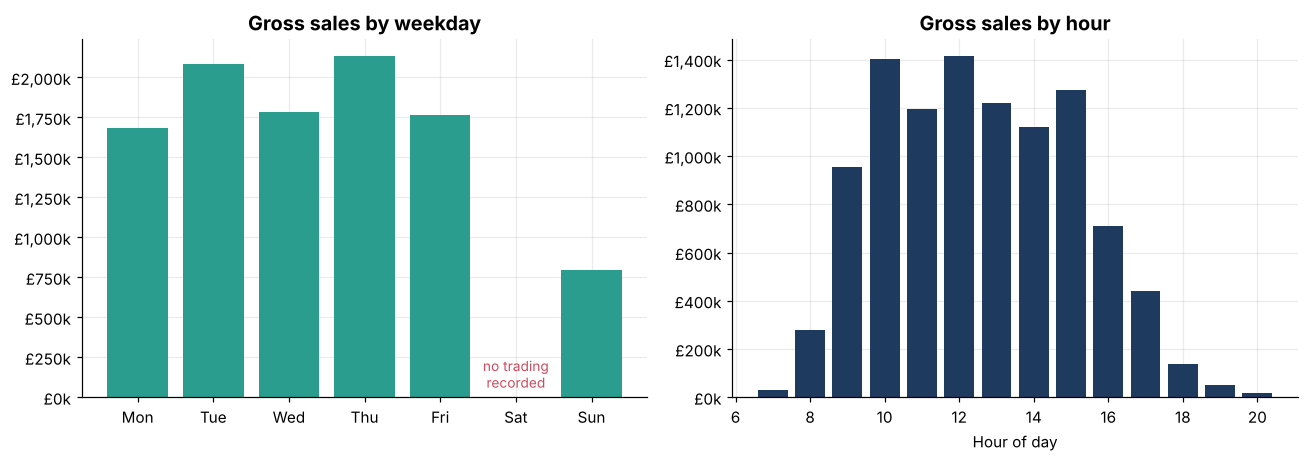

In [11]:
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day  = sales.groupby(sales.InvoiceDate.dt.day_name()).Revenue.sum().reindex(days).fillna(0)
by_hour = sales.groupby(sales.InvoiceDate.dt.hour).Revenue.sum()
by_hour = by_hour[(by_hour.index >= 7) & (by_hour.index <= 20)]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
cols_ = [RED if d == "Saturday" else TEAL for d in days]
axes[0].bar([d[:3] for d in days], by_day.values, color=cols_)
axes[0].yaxis.set_major_formatter(gbp_k); axes[0].set_title("Gross sales by weekday")
axes[0].text(5, 60000, "no trading\nrecorded", ha="center", color=RED, fontsize=9)
axes[1].bar(by_hour.index, by_hour.values, color=NAVY)
axes[1].yaxis.set_major_formatter(gbp_k); axes[1].set_xlabel("Hour of day"); axes[1].set_title("Gross sales by hour")
fig.tight_layout(); save(fig, "02_weekday_hour.png")
M.update(peak_day=by_day.idxmax(), peak_hours_share=by_hour.loc[10:15].sum() / by_hour.sum(), sunday_share=by_day["Sunday"] / by_day.sum())
print(f"Peak weekday: {by_day.idxmax()} | 10:00-15:59 carries {M['peak_hours_share']:.0%} of sales | Sunday = {M['sunday_share']:.0%}")

## 6. Top-selling products
Products are keyed on `StockCode` (with one cleaned description each) and ranked on **net** figures, so cancelled orders do not distort the ranking.

,Description,gross,returned_value,net_revenue,net_units,orders
StockCode,,,,,,
22423,REGENCY CAKESTAND 3 TIER,"174,156.54","-9,697.05","164,459.49","12,996.00","1,988.00"
47566,PARTY BUNTING,"99,445.23","-1,201.35","98,243.88","18,006.00","1,685.00"
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"104,462.75","-6,624.30","97,838.45","35,063.00","2,198.00"
85099B,JUMBO BAG RED RETROSPOT,"94,159.81","-1,984.02","92,175.79","47,256.00","2,089.00"
23084,RABBIT NIGHT LIGHT,"66,870.03",-208.40,"66,661.63","30,631.00",994.00
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"64,875.59","-1,160.35","63,715.24","18,876.00","1,160.00"
84879,ASSORTED COLOUR BIRD ORNAMENT,"58,927.62",-135.20,"58,792.42","36,282.00","1,455.00"
79321,CHILLI LIGHTS,"54,096.36",-349.70,"53,746.66","10,222.00",661.00
22502,PICNIC BASKET WICKER SMALL,"51,408.77",-385.25,"51,023.52","1,862.00",463.00


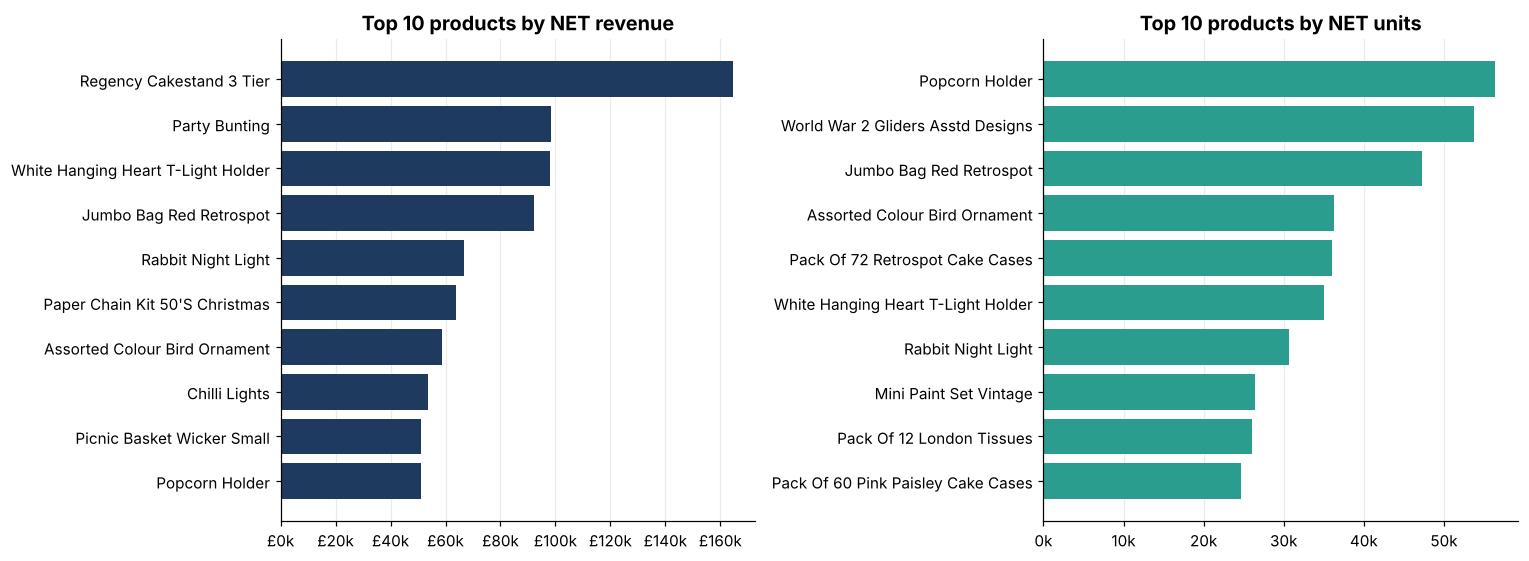

In [12]:
p_s = sales.groupby("StockCode").agg(gross=("Revenue", "sum"), units=("Quantity", "sum"), orders=("InvoiceNo", "nunique"))
p_r = returns.groupby("StockCode").agg(returned_value=("Revenue", "sum"), returned_units=("Quantity", "sum"))
products = p_s.join(p_r, how="outer").fillna(0)
products["net_revenue"] = products.gross + products.returned_value
products["net_units"]   = products.units + products.returned_units
products["Description"] = products.index.map(desc_map)
products = products.sort_values("net_revenue", ascending=False)

top_rev   = products.head(10)
top_units = products.sort_values("net_units", ascending=False).head(10)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
axes[0].barh([short(x) for x in top_rev.Description][::-1], top_rev.net_revenue[::-1], color=NAVY)
axes[0].xaxis.set_major_formatter(gbp_k); axes[0].set_title("Top 10 products by NET revenue")
axes[1].barh([short(x) for x in top_units.Description][::-1], top_units.net_units[::-1], color=TEAL)
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{x/1e3:,.0f}k")); axes[1].set_title("Top 10 products by NET units")
for a in axes: a.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "03_top_products.png")

products.reset_index().to_csv(OUT / "product_summary.csv", index=False)
top_rev[["Description", "gross", "returned_value", "net_revenue", "net_units", "orders"]]

In [13]:
# Gross vs net ranking: shows how the two cancelled mega-orders distort a naive "best seller" list
gross_rank = products.gross.rank(ascending=False).astype(int)
net_rank   = products.net_revenue.rank(ascending=False).astype(int)
cmp_ = pd.DataFrame({"Description": products.Description, "gross_rank": gross_rank, "net_rank": net_rank,
                     "gross": products.gross, "net_revenue": products.net_revenue})
cmp_.sort_values("gross_rank").head(5)

,Description,gross_rank,net_rank,gross,net_revenue
StockCode,,,,,
22423,REGENCY CAKESTAND 3 TIER,1,1,"174,156.54","164,459.49"
23843,"PAPER CRAFT , LITTLE BIRDIE",2,3893,"168,469.60",0.00
85123A,WHITE HANGING HEART T-LIGHT HOLDER,3,3,"104,462.75","97,838.45"
47566,PARTY BUNTING,4,2,"99,445.23","98,243.88"
85099B,JUMBO BAG RED RETROSPOT,5,4,"94,159.81","92,175.79"


Top 10 products = 8.2% of net revenue; top 20 = 12.0%
840 of 3,891 products (22%) generate 80% of net revenue

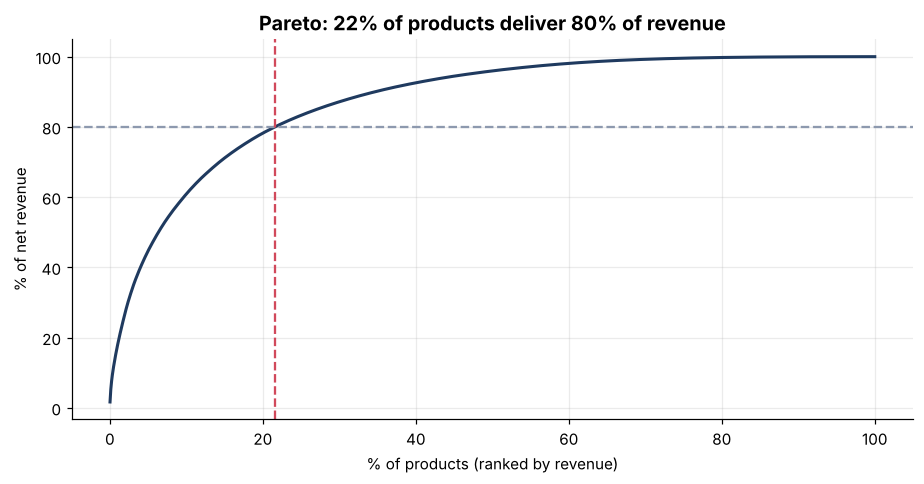

In [14]:
# Pareto: how concentrated is revenue across products?
p = products[products.net_revenue > 0].net_revenue.sort_values(ascending=False)
cum = p.cumsum() / p.sum()
n80 = int((cum <= .80).sum() + 1)
M.update(top10_share=p.head(10).sum() / p.sum(), top20_share=p.head(20).sum() / p.sum(),
         n_skus=len(p), n80=n80, share_skus_80=n80 / len(p))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(np.arange(1, len(p) + 1) / len(p) * 100, cum.values * 100, color=NAVY, lw=2)
ax.axhline(80, color=GREY, ls="--"); ax.axvline(n80 / len(p) * 100, color=RED, ls="--")
ax.set_xlabel("% of products (ranked by revenue)"); ax.set_ylabel("% of net revenue")
ax.set_title(f"Pareto: {n80/len(p):.0%} of products deliver 80% of revenue")
fig.tight_layout(); save(fig, "04_pareto_products.png")
print(f"Top 10 products = {M['top10_share']:.1%} of net revenue; top 20 = {M['top20_share']:.1%}")
print(f"{n80:,} of {len(p):,} products ({n80/len(p):.0%}) generate 80% of net revenue")

**Takeaways.** The gross ranking is topped by the two cancelled mega-orders; on a **net** basis the genuine hero products are the *Regency Cakestand 3-Tier*, *White Hanging Heart T-Light Holder*, *Party Bunting* and *Jumbo Bag Red Retrospot*. Revenue is only moderately concentrated: no single product exceeds ~2% of net revenue and the top 10 together make up ~8%, but about a fifth of the range delivers 80% – so a tiered (ABC) stock policy makes more sense than guarding a handful of heroes.

## 7. High-value product categories
The dataset has **no category column**, so categories are *derived* from product descriptions with ordered keyword rules (first match wins). This is a heuristic grouping – reasonable for strategic insight, but not a substitute for the retailer's own product hierarchy.

In [15]:
RULES = [
 ("Christmas & Seasonal",     r"CHRISTMAS|XMAS|ADVENT|SANTA|REINDEER|SNOW|EASTER|HALLOWEEN|STOCKING|TINSEL"),
 ("Party, Cards & Gift Wrap", r"BUNTING|WRAP|CARD|GIFT|PARTY|BALLOON|BIRTHDAY|RIBBON|BANNER|CONFETTI|PARASOL|GARLAND|TISSUE"),
 ("Lighting & Candles",       r"LIGHT|LANTERN|CANDLE|LAMP|FAIRY LIGHT|INCENSE"),
 ("Bags & Accessories",       r"\bBAG\b|BAGS|PURSE|WALLET|UMBRELLA|SHOPPER|RUCKSACK|SCARF|\bHAT\b|GLOVES|SUNGLASSES|KEYRING|KEY RING"),
 ("Jewellery",                r"NECKLACE|BRACELET|EARRING|CHARM|BEADS|BROOCH|\bRING\b|JEWEL|PENDANT"),
 ("Home Décor",               r"FAIRY CAKE|FRAME|MIRROR|CLOCK|CUSHION|DOORMAT|HEART|DECORATION|ORNAMENT|VASE|WREATH|FIGURINE|PHOTO|BLANKET|THROW|HANGING|SOAP|BATH"),
 ("Kitchen & Dining",         r"MUG|\bCUPS?\b|EGGCUP|\bPLATES?\b|BOWL|JAR|CAKESTAND|CAKE STAND|CAKE CASES|CAKE TIN|\bTEA\b|TEAPOT|SPOON|\bTIN\b|\bTINS\b|KITCHEN|CUTLERY|BAKING|APRON|GLASS|JUG|COASTER|NAPKIN|SALT|PEPPER|BOTTLE|COOK|FORK|KNIFE|TRAY|PLACEMAT|SPATULA|MUFFIN|SANDWICH|LUNCH|PICNIC|EGG|PANTRY|\bJAM\b"),
 ("Stationery & Craft",       r"PAPER|NOTEBOOK|PENCIL|\bPEN\b|STICKER|STATIONERY|CRAFT|ERASER|RUBBER|DIARY|CALENDAR|JOURNAL|BOOK|RULER|STAMP|POSTCARD|SEWING|KNITTING|SCISSORS"),
 ("Toys & Games",             r"TOY|GAME|PUZZLE|DOLL|PLAYING|DOLLY|SKITTLES|DOMINOES|SPACEBOY|SPACE BOY|ROBOT|TEDDY|GLIDER|PLAY|CHILDREN|CHILDS|KIDS|BUBBLE"),
 ("Storage & Organisation",   r"BOX|BASKET|STORAGE|DRAWER|CABINET|TRUNK|CRATE|CHEST|HOLDER|RACK|HOOK|SHELF|\bBIN\b"),
 ("Garden & Outdoor",         r"GARDEN|PLANT|FLOWER|BIRD|WATERING|\bPOT\b|POTS|OUTDOOR|SEED|HERB|WINDMILL|FEEDER"),
]
def categorize(desc):
    for name, pattern in RULES:
        if re.search(pattern, str(desc)):
            return name
    return "Other"

cat_map = desc_map.map(categorize)
for t in (sales, returns, sales_adj, returns_adj):
    t["Category"] = t.StockCode.map(cat_map).fillna("Other")
products["Category"] = products.index.map(cat_map)
print(f"{(products.Category == 'Other').mean():.1%} of products (and {products.loc[products.Category=='Other','net_revenue'].sum()/products.net_revenue.sum():.1%} of net revenue) fall in 'Other'")

15.1% of products (and 12.0% of net revenue) fall in 'Other'

,net_revenue,share_%,units,avg_unit_price,return_rate_%,skus
Category,,,,,,
Kitchen & Dining,"2,262,902.28",23.16,1075744,2.23,2.66,620
Home Décor,"1,608,408.99",16.46,701871,2.35,2.37,575
Other,"1,169,540.36",11.97,681071,1.75,1.73,592
Bags & Accessories,"1,110,700.82",11.37,634701,1.78,1.68,224
"Party, Cards & Gift Wrap","840,283.53",8.60,691205,1.23,1.54,388
Lighting & Candles,"791,583.58",8.10,465967,1.75,3.17,359
Storage & Organisation,"604,316.71",6.18,266569,2.33,2.84,173
Christmas & Seasonal,"526,868.54",5.39,351915,1.53,2.06,235
Stationery & Craft,"465,780.14",4.77,425391,1.53,3.17,219


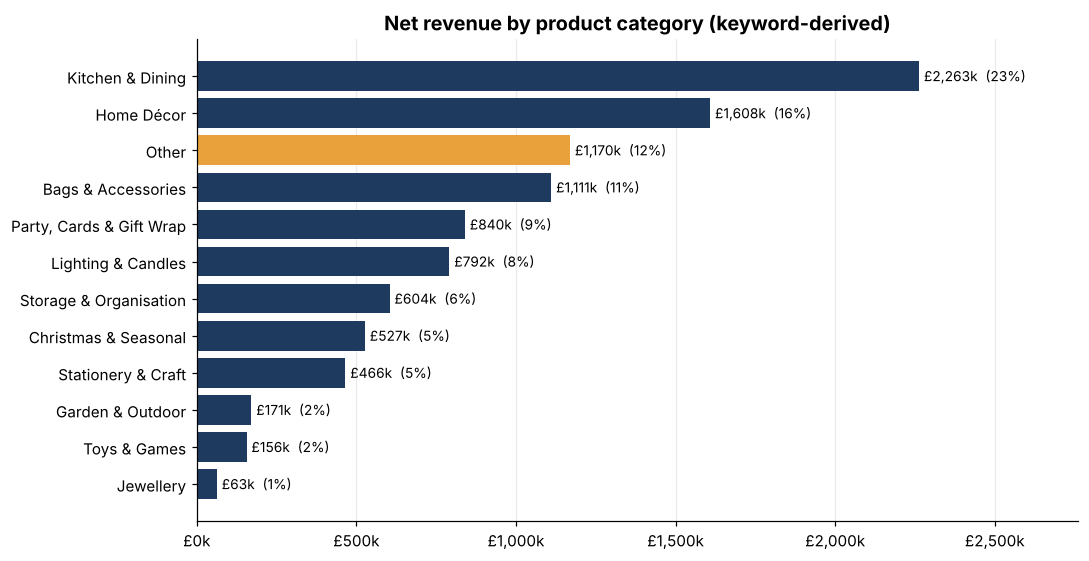

In [16]:
cat = sales.groupby("Category").agg(gross=("Revenue", "sum"), units=("Quantity", "sum"), orders=("InvoiceNo", "nunique"))
cat["returns"] = -returns.groupby("Category").Revenue.sum()
cat["net_revenue"] = cat.gross - cat.returns
cat["share_%"] = cat.net_revenue / cat.net_revenue.sum() * 100
cat["return_rate_%"] = (-returns_adj.groupby("Category").Revenue.sum()) / sales_adj.groupby("Category").Revenue.sum() * 100   # underlying
cat["avg_unit_price"] = cat.gross / cat.units
cat["skus"] = products.groupby("Category").size()
cat = cat.sort_values("net_revenue", ascending=False)
cat.to_csv(OUT / "category_summary.csv")
M.update(top_cat=cat.index[0], top_cat_share=cat["share_%"].iloc[0] / 100,
         top3_cat_share=cat["share_%"].head(3).sum() / 100)

fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.barh(cat.index[::-1], cat.net_revenue[::-1], color=[AMBER if c == "Other" else NAVY for c in cat.index[::-1]])
for b, v, s in zip(bars, cat.net_revenue[::-1], cat["share_%"][::-1]):
    ax.text(v + 15000, b.get_y() + b.get_height() / 2, f"£{v/1e3:,.0f}k  ({s:.0f}%)", va="center", fontsize=9)
ax.xaxis.set_major_formatter(gbp_k); ax.set_xlim(0, cat.net_revenue.max() * 1.22); ax.grid(axis="y", visible=False)
ax.set_title("Net revenue by product category (keyword-derived)")
fig.tight_layout(); save(fig, "05_category_revenue.png")
cat[["net_revenue", "share_%", "units", "avg_unit_price", "return_rate_%", "skus"]]

Christmas & Seasonal averages index 303 in Sep-Nov 2011 (vs 100 across the year)

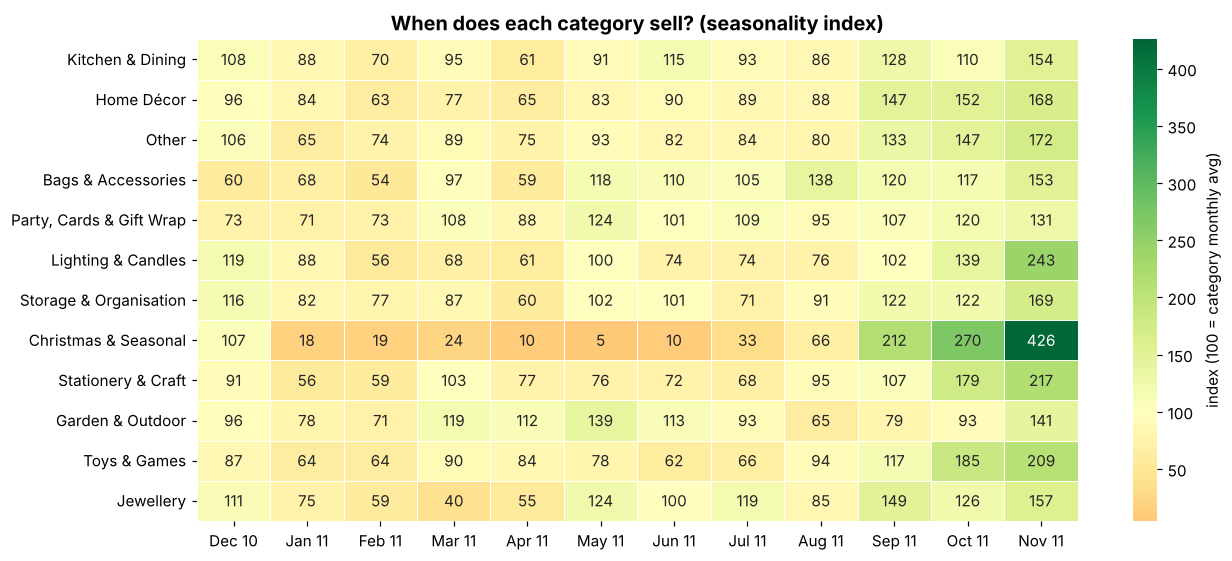

In [17]:
# Seasonality by category (gross sales, mega-orders excluded): month revenue relative to that category's own monthly average (100 = average)
cm = sales_adj.pivot_table(index="Category", columns="Month", values="Revenue", aggfunc="sum")   # excludes the 2 cancelled mega-orders
cm = cm.loc[:, cm.columns < "2011-12-01"]                       # full months only
idx = cm.div(cm.mean(axis=1), axis=0) * 100
idx = idx.loc[cat.index]; idx.columns = idx.columns.strftime("%b %y")
fig, ax = plt.subplots(figsize=(12, 5.2))
sns.heatmap(idx, cmap="RdYlGn", center=100, annot=True, fmt=".0f", linewidths=.5, cbar_kws={"label": "index (100 = category monthly avg)"}, ax=ax)
ax.set_title("When does each category sell? (seasonality index)"); ax.set_xlabel(""); ax.set_ylabel("")
fig.tight_layout(); save(fig, "06_category_seasonality.png")
xm = idx.loc["Christmas & Seasonal", ["Sep 11", "Oct 11", "Nov 11"]].mean()
print(f"Christmas & Seasonal averages index {xm:.0f} in Sep-Nov 2011 (vs 100 across the year)")

**Takeaways.** *Kitchen & Dining* and *Home Décor* are the two largest categories. Christmas & Seasonal products are extremely time-concentrated (the heatmap shows the Sep–Nov spike), which is a planning and cash-flow issue – stock must be bought months before it sells.

## 8. Regional performance

In [18]:
cs = sales.groupby("Country").agg(gross=("Revenue", "sum"), orders=("InvoiceNo", "nunique"),
                                  customers=("CustomerID", "nunique"), units=("Quantity", "sum"))
cs["returns"] = -returns.groupby("Country").Revenue.sum()
cs = cs.fillna(0)
ret_adj_c = -returns_adj.groupby("Country").Revenue.sum()
gross_adj_c = sales_adj.groupby("Country").Revenue.sum()
cs["net_revenue"]   = cs.gross - cs.returns
cs["share_%"]       = cs.net_revenue / cs.net_revenue.sum() * 100
cs["aov"]           = cs.gross / cs.orders
cs["rev_per_cust"]  = (cs.gross / cs.customers.replace(0, np.nan))
cs["return_rate_%"] = (ret_adj_c.reindex(cs.index).fillna(0) / gross_adj_c.reindex(cs.index)) * 100   # underlying
cs = cs.sort_values("net_revenue", ascending=False)
cs.to_csv(OUT / "country_summary.csv")

uk_share = cs.loc["United Kingdom", "share_%"] / 100
intl = cs.drop("United Kingdom")
M.update(uk_share=uk_share, intl_share=1 - uk_share, n_countries=len(cs), top_intl=intl.index[0],
         top_intl_net=intl.net_revenue.iloc[0], top5_intl_share=intl.net_revenue.head(5).sum() / cs.net_revenue.sum())
print(f"UK = {uk_share:.1%} of net revenue; the other {len(cs)-1} countries = {1-uk_share:.1%}")
cs.head(10)[["net_revenue", "share_%", "orders", "customers", "aov", "rev_per_cust", "return_rate_%"]]

UK = 84.8% of net revenue; the other 37 countries = 15.2%

,net_revenue,share_%,orders,customers,aov,rev_per_cust,return_rate_%
Country,,,,,,,
United Kingdom,"8,280,991.91",84.75,17901,3916,487.35,"2,227.80",2.33
Netherlands,"283,479.54",2.90,93,9,"3,052.57","31,543.26",0.14
EIRE,"259,380.02",2.65,282,3,960.46,"90,283.62",4.24
Germany,"200,619.66",2.05,443,94,463.61,"2,184.91",2.32
France,"182,076.60",1.86,382,87,482.97,"2,120.61",1.31
Australia,"136,922.50",1.40,56,9,"2,466.14","15,344.87",0.86
Switzerland,"52,483.05",0.54,50,21,"1,061.31","2,526.93",1.10
Spain,"51,746.65",0.53,88,30,633.03,"1,856.89",7.11
Belgium,"36,662.96",0.38,98,25,376.81,"1,477.09",0.72


,customers,net_revenue,rev_per_cust,aov
Country,,,,
Netherlands,9,"283,479.54","31,543.26","3,052.57"
EIRE,3,"259,380.02","90,283.62",960.46
Germany,94,"200,619.66","2,184.91",463.61
France,87,"182,076.60","2,120.61",482.97
Australia,9,"136,922.50","15,344.87","2,466.14"
Switzerland,21,"52,483.05","2,526.93","1,061.31"
Spain,30,"51,746.65","1,856.89",633.03
Belgium,25,"36,662.96","1,477.09",376.81
Japan,8,"35,419.79","4,677.05","1,969.28"


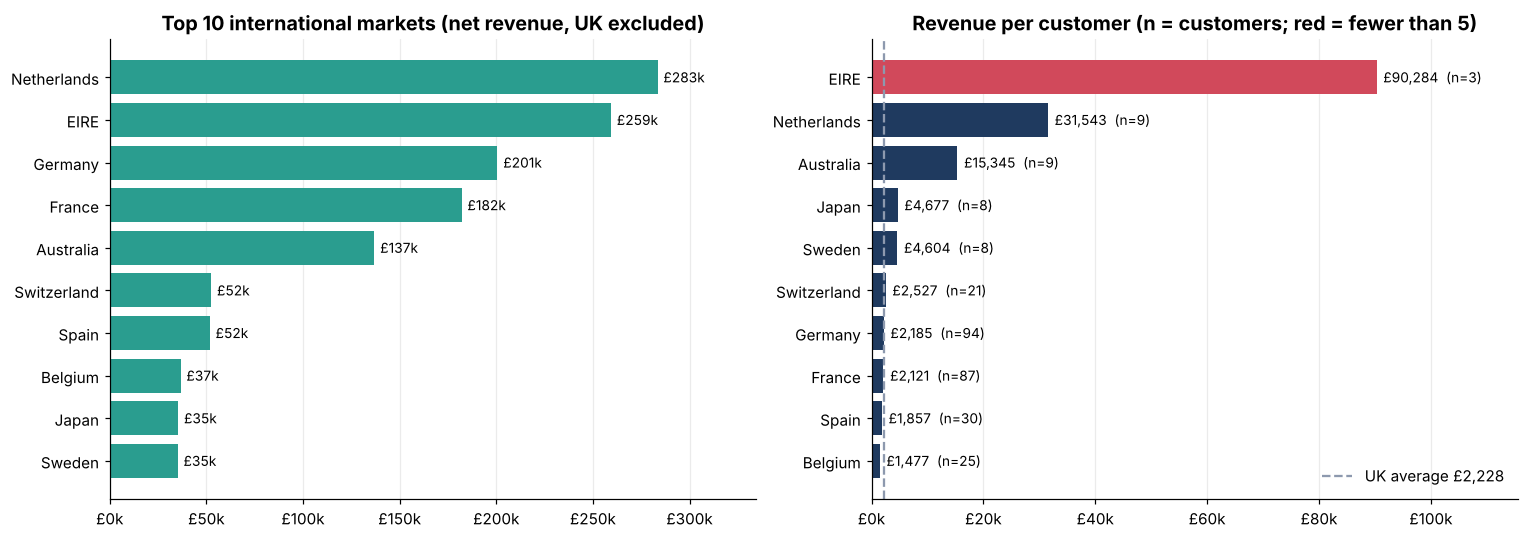

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
t10 = intl.head(10)
bars = axes[0].barh(t10.index[::-1], t10.net_revenue[::-1], color=TEAL)
for b, v in zip(bars, t10.net_revenue[::-1]):
    axes[0].text(v + 3000, b.get_y() + b.get_height() / 2, f"£{v/1e3:,.0f}k", va="center", fontsize=9)
axes[0].xaxis.set_major_formatter(gbp_k); axes[0].set_xlim(0, t10.net_revenue.max() * 1.18)
axes[0].set_title("Top 10 international markets (net revenue, UK excluded)"); axes[0].grid(axis="y", visible=False)

# Customer value in the top international markets (n = identified customers shown on each bar)
t10 = intl.head(10)
rpc = t10.rev_per_cust.sort_values()
bars = axes[1].barh(rpc.index, rpc.values, color=[RED if t10.loc[c, "customers"] < 5 else NAVY for c in rpc.index])
for b, c in zip(bars, rpc.index):
    axes[1].text(b.get_width() + 1200, b.get_y() + b.get_height() / 2,
                 f"£{rpc[c]:,.0f}  (n={int(t10.loc[c, 'customers'])})", va="center", fontsize=9)
uk_rpc = cs.loc["United Kingdom", "rev_per_cust"]
axes[1].axvline(uk_rpc, color=GREY, ls="--", label=f"UK average £{uk_rpc:,.0f}"); axes[1].legend(loc="lower right", frameon=False)
axes[1].set_xlim(0, rpc.max() * 1.28); axes[1].grid(axis="y", visible=False)
axes[1].xaxis.set_major_formatter(FuncFormatter(lambda x, p: f"£{x/1e3:,.0f}k"))
axes[1].set_title("Revenue per customer (n = customers; red = fewer than 5)")
fig.tight_layout(); save(fig, "07_country_performance.png")

intl.head(10)[["customers", "net_revenue", "rev_per_cust", "aov"]]

**Takeaways.** The UK is ~85% of revenue, so the business is heavily domestic. International revenue is concentrated in five markets, but they behave very differently:
* **Netherlands, EIRE and Australia** are *wholesale-account* markets – a handful of customers (9, 3 and 9) each spending £15k–£90k. High value, but fragile: losing one account moves the country noticeably.
* **Germany and France** are *broad-base* markets – ~90 customers each, spending about the same per customer as UK customers. Slower to build but far more resilient.

## 9. Customer concentration and returns
Customer metrics use only the ~75% of lines that carry a `CustomerID`.

Top 10% of customers = 60.2% of identified revenue; top 20% = 73.8%
Repeat customers (2+ orders) = 65.3% of customers but 93.5% of revenue

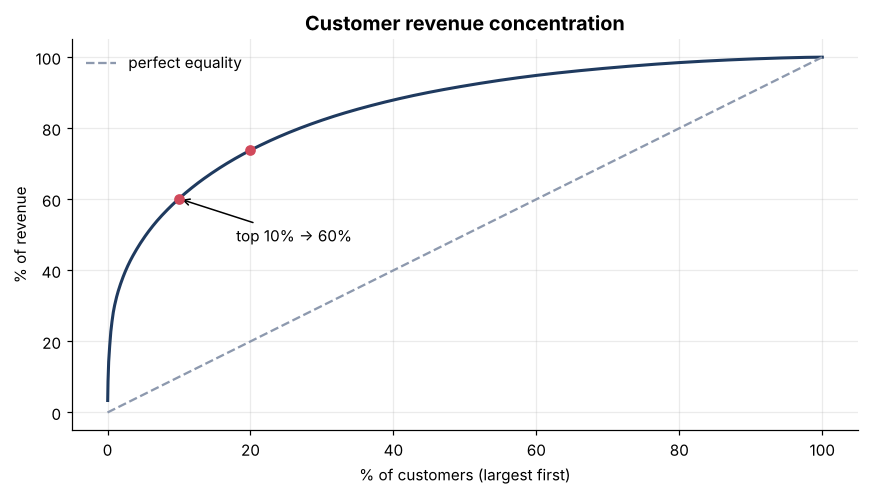

In [20]:
cust = (sales.dropna(subset=["CustomerID"]).groupby("CustomerID")
        .agg(gross_rev=("Revenue", "sum"), orders=("InvoiceNo", "nunique")))
cust["revenue"] = cust.gross_rev + returns.dropna(subset=["CustomerID"]).groupby("CustomerID").Revenue.sum().reindex(cust.index).fillna(0)  # NET of returns
cust = cust.sort_values("revenue", ascending=False)
cumc = cust.revenue.cumsum() / cust.revenue.sum()
top10 = cust.revenue.head(int(len(cust) * .10)).sum() / cust.revenue.sum()
top20 = cust.revenue.head(int(len(cust) * .20)).sum() / cust.revenue.sum()
repeat = (cust.orders > 1).mean()
repeat_rev = cust.loc[cust.orders > 1, "revenue"].sum() / cust.revenue.sum()
M.update(cust_top10=top10, cust_top20=top20, repeat_cust_share=repeat, repeat_rev_share=repeat_rev,
         top10_customers_share=cust.revenue.head(10).sum() / cust.revenue.sum())

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.plot(np.arange(1, len(cust) + 1) / len(cust) * 100, cumc.values * 100, color=NAVY, lw=2)
ax.plot([0, 100], [0, 100], color=GREY, ls="--", label="perfect equality")
ax.scatter([10, 20], [top10 * 100, top20 * 100], color=RED, zorder=5)
ax.annotate(f"top 10% -> {top10:.0%}", (10, top10 * 100), xytext=(18, top10 * 100 - 12), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("% of customers (largest first)"); ax.set_ylabel("% of revenue"); ax.legend(frameon=False)
ax.set_title("Customer revenue concentration"); fig.tight_layout(); save(fig, "08_customer_concentration.png")
print(f"Top 10% of customers = {top10:.1%} of identified revenue; top 20% = {top20:.1%}")
print(f"Repeat customers (2+ orders) = {repeat:.1%} of customers but {repeat_rev:.1%} of revenue")

Underlying return rate 2.3% (recorded 4.6%); worst month Apr 2011 at 6.5%; worst category Stationery & Craft at 3.2%

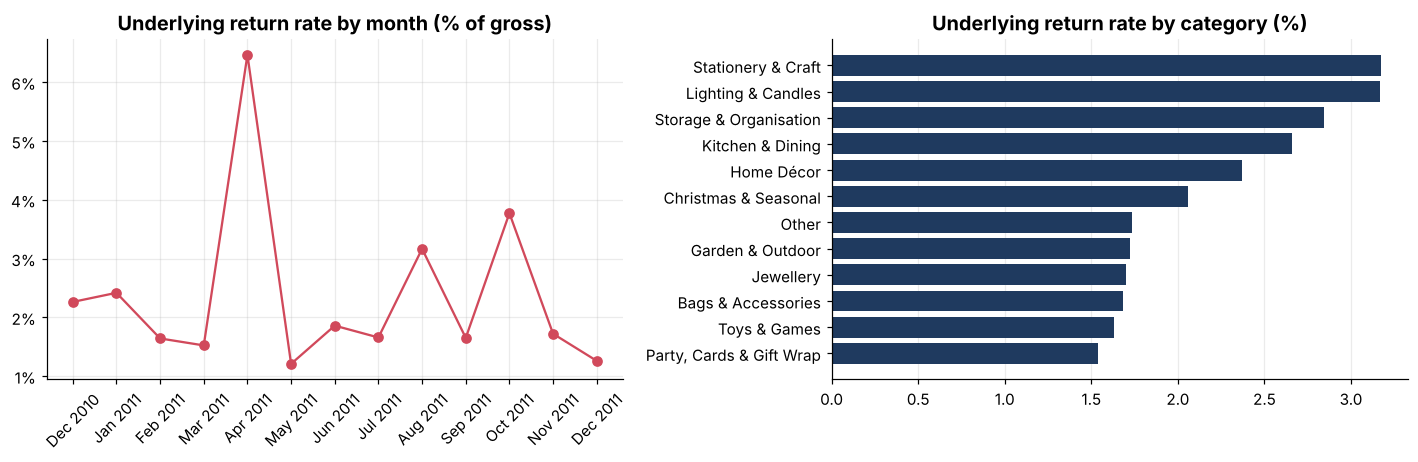

In [21]:
mr = (-returns_adj.groupby("Month").Revenue.sum() / sales_adj.groupby("Month").Revenue.sum() * 100).fillna(0)
mr.index = mr.index.strftime("%b %Y")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
axes[0].plot(mr.index, mr.values, marker="o", color=RED); axes[0].set_title("Underlying return rate by month (% of gross)")
axes[0].tick_params(axis="x", rotation=45); axes[0].yaxis.set_major_formatter(FuncFormatter(lambda x, p: f"{x:.0f}%"))
rc = cat["return_rate_%"].sort_values()
axes[1].barh(rc.index, rc.values, color=NAVY); axes[1].set_title("Underlying return rate by category (%)"); axes[1].grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "09_returns.png")
M.update(worst_return_month=mr.idxmax(), worst_return_rate=mr.max() / 100,
         worst_return_cat=rc.index[-1], worst_return_cat_rate=rc.iloc[-1] / 100)
print(f"Underlying return rate {M['return_rate_underlying']:.1%} (recorded {M['return_rate']:.1%}); worst month {mr.idxmax()} at {mr.max():.1f}%; worst category {rc.index[-1]} at {rc.iloc[-1]:.1f}%")

**Reading this.** Once the two mega-orders are set aside, returns are low (~2%) and fairly even across categories (all under ~3.5%). The April 2011 spike is *not* a product-quality problem: it comes from one customer (15749) cancelling a large order (`C550456`) and **re-placing the same order 12 minutes later** (`550461`) – an order amendment recorded as a cancellation. Small markets such as Spain show higher rates (7%) on very few orders, so treat those with caution.

## 10. One-page executive dashboard
A client-ready summary combining the KPIs and the main charts.

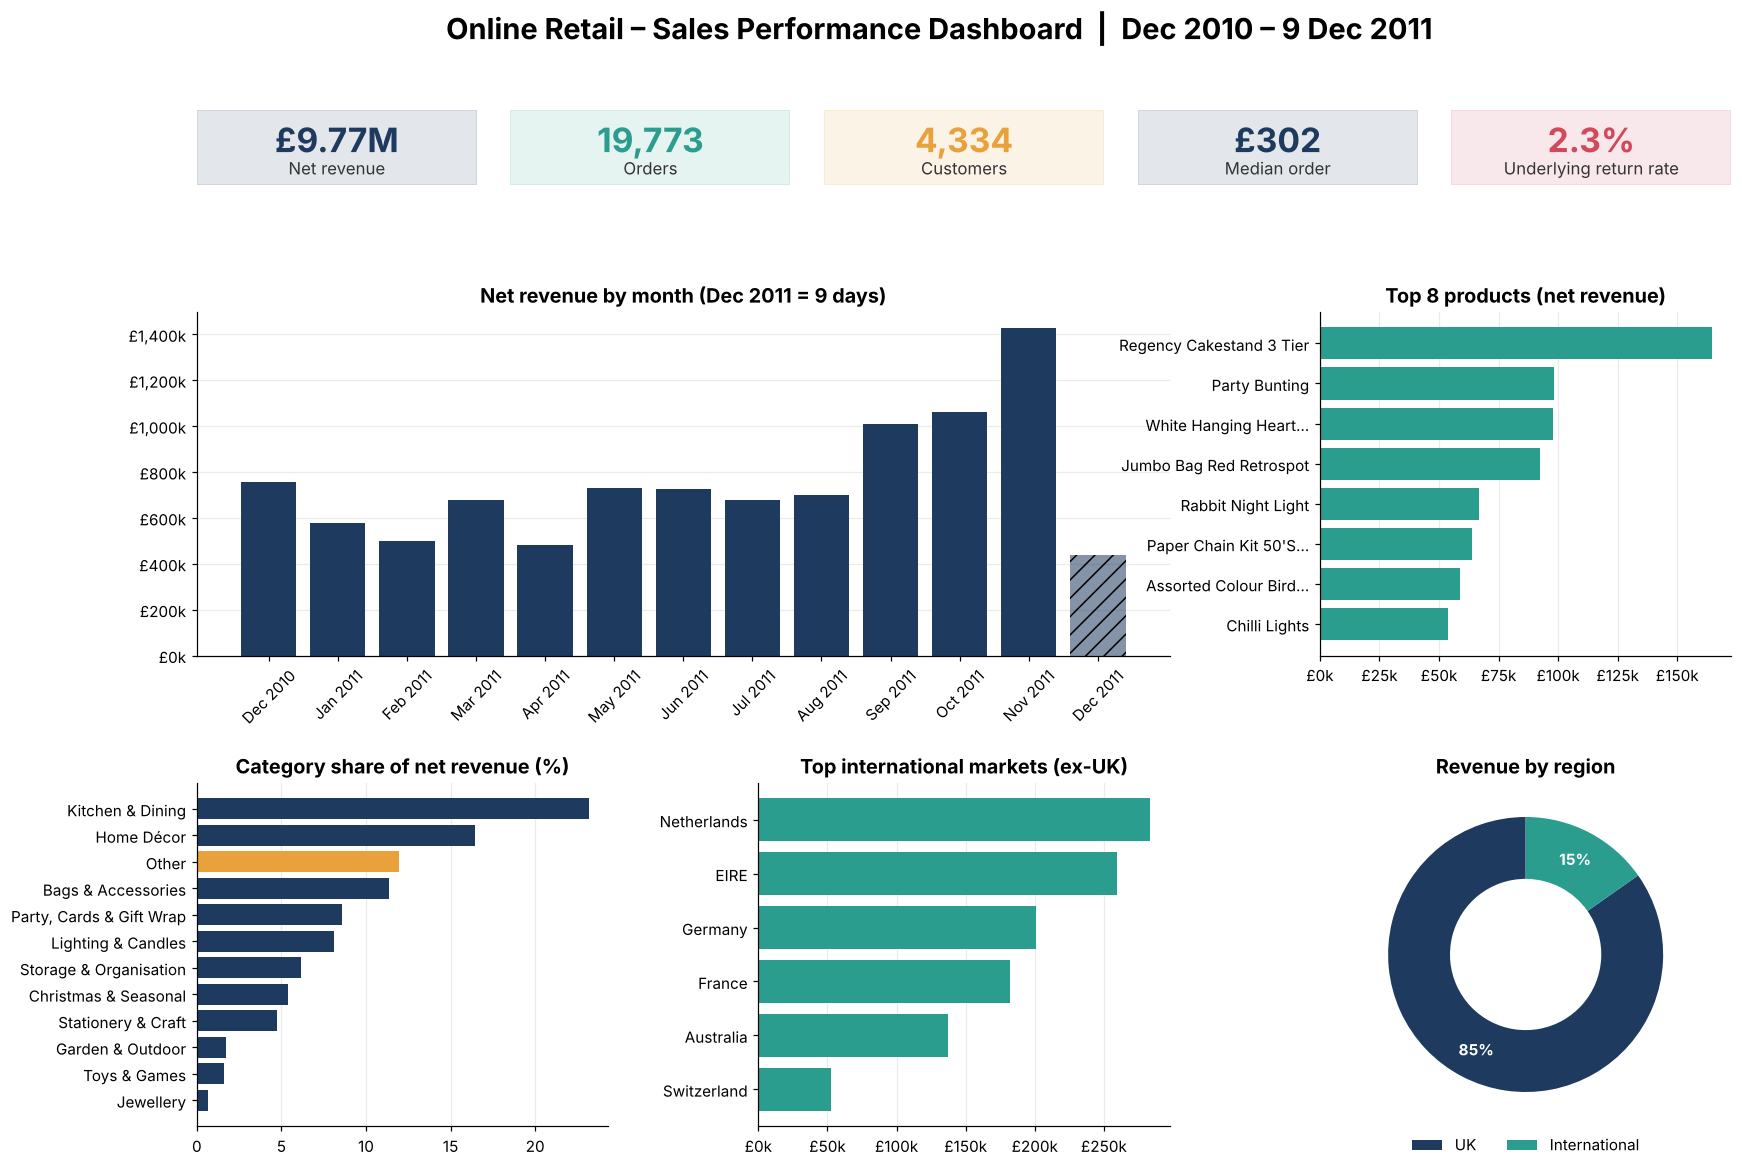

In [22]:
fig = plt.figure(figsize=(18, 12), facecolor="white")
gs = fig.add_gridspec(3, 6, height_ratios=[.5, 2.3, 2.3], hspace=.5, wspace=1.15)
fig.suptitle("Online Retail – Sales Performance Dashboard  |  Dec 2010 – 9 Dec 2011", fontsize=19, fontweight="bold", y=.955)

tiles = [("Net revenue", gbp(M["net"]), NAVY), ("Orders", f"{M['orders']:,}", TEAL),
         ("Customers", f"{M['customers']:,}", AMBER), ("Median order", f"£{M['aov_median']:,.0f}", NAVY),
         ("Underlying return rate", f"{M['return_rate_underlying']:.1%}", RED)]
gs_t = gs[0, :].subgridspec(1, 5, wspace=.12)
for i, (lab, val, colr) in enumerate(tiles):
    a = fig.add_subplot(gs_t[0, i]); a.axis("off")
    a.add_patch(plt.Rectangle((0, 0), 1, 1, transform=a.transAxes, color=colr, alpha=.12))
    a.text(.5, .60, val, ha="center", va="center", fontsize=22, fontweight="bold", color=colr, transform=a.transAxes)
    a.text(.5, .22, lab, ha="center", va="center", fontsize=11, color="#333", transform=a.transAxes)

a1 = fig.add_subplot(gs[1, :4])
b = a1.bar(monthly.index, monthly.net, color=NAVY); b[-1].set_hatch("//"); b[-1].set_alpha(.55)
a1.yaxis.set_major_formatter(gbp_k); a1.tick_params(axis="x", rotation=45); a1.grid(axis="x", visible=False)
a1.set_title("Net revenue by month (Dec 2011 = 9 days)")

a2 = fig.add_subplot(gs[1, 4:])
t8 = products.head(8)
a2.barh([short(x, 26) for x in t8.Description][::-1], t8.net_revenue[::-1], color=TEAL)
a2.xaxis.set_major_formatter(gbp_k); a2.grid(axis="y", visible=False); a2.set_title("Top 8 products (net revenue)")

a3 = fig.add_subplot(gs[2, :2])
a3.barh(cat.index[::-1], cat["share_%"][::-1], color=[AMBER if c == "Other" else NAVY for c in cat.index[::-1]])
a3.set_title("Category share of net revenue (%)"); a3.grid(axis="y", visible=False)

a4 = fig.add_subplot(gs[2, 2:4])
t6 = intl.head(6)
a4.barh(t6.index[::-1], t6.net_revenue[::-1], color=TEAL); a4.xaxis.set_major_formatter(gbp_k)
a4.set_title("Top international markets (ex-UK)"); a4.grid(axis="y", visible=False)

a5 = fig.add_subplot(gs[2, 4:])
_, _, ats = a5.pie([uk_share, 1 - uk_share], colors=[NAVY, TEAL], autopct="%1.0f%%", pctdistance=.78,
       startangle=90, wedgeprops=dict(width=.45))
for t_ in ats: t_.set_color("white"); t_.set_fontweight("bold")
a5.legend(["UK", "International"], loc="lower center", bbox_to_anchor=(.5, -.12), ncol=2, frameon=False)
a5.set_title("Revenue by region")
save(fig, "00_dashboard.png")

## 11. Key findings
The text below is generated from the computed results, so the numbers always match the analysis.

In [23]:
nl, au, ie = (int(cs.loc[c, 'customers']) for c in ('Netherlands', 'Australia', 'EIRE'))
de, fr = (int(cs.loc[c, 'customers']) for c in ('Germany', 'France'))
display(Markdown(f"""
1. **Revenue.** Net revenue was **£{M['net']:,.0f}** ({gbp(M['gross'])} gross less {gbp(M['returns'])} of returns, a **{M['return_rate']:.1%}** recorded return rate, **{M['return_rate_underlying']:.1%}** underlying once the two cancelled mega-orders are removed) from **{M['orders']:,} orders** and **{M['customers']:,} identified customers**.
2. **Seasonality.** Sep–Nov 2011 produced **{M['q4_share']:.0%}** of Jan–Nov net revenue (27% if flat); the best month, **{M['best_month']}**, delivered {gbp(M['best_month_net'])} – **{M['nov_vs_h1']:.1f}×** the Jan–Aug monthly average. On a like-for-like basis, 1–9 December net revenue moved **{M['dec9_growth']:+.0%}** year on year.
3. **Products.** The top 10 products earn **{M['top10_share']:.0%}** of net revenue, and just **{M['share_skus_80']:.0%}** of products ({M['n80']:,} of {M['n_skus']:,}) deliver 80%. Gross rankings are distorted by two cancelled mega-orders (~£246k).
4. **Categories.** **{M['top_cat']}** leads with **{M['top_cat_share']:.0%}** of net revenue; the top three categories together account for **{M['top3_cat_share']:.0%}**.
5. **Regions.** The UK provides **{M['uk_share']:.0%}** of net revenue; the other {M['n_countries']-1} countries share **{M['intl_share']:.0%}**, led by **{M['top_intl']}** ({gbp(M['top_intl_net'])}). The five largest international markets make up {M['top5_intl_share']:.0%} of total revenue.
6. **Customers.** The top 10% of identified customers generate **{M['cust_top10']:.0%}** of revenue; repeat customers are {M['repeat_cust_share']:.0%} of the base but **{M['repeat_rev_share']:.0%}** of revenue – a wholesale-style, relationship-driven business.
7. **Trading pattern.** **{M['peak_day']}** is the strongest weekday, 10:00–15:59 carries **{M['peak_hours_share']:.0%}** of sales, and no sales are recorded on Saturdays.
8. **Data gap.** **{M['unidentified_rev_share']:.0%}** of revenue is not linked to a customer ID, which limits retention and CLV analysis.
"""))


1. **Revenue.** Net revenue was **£9,770,920** (£10.25M gross less £476k of returns, a **4.6%** recorded return rate, **2.3%** underlying once the two cancelled mega-orders are removed) from **19,773 orders** and **4,334 identified customers**.
2. **Seasonality.** Sep–Nov 2011 produced **41%** of Jan–Nov net revenue (27% if flat); the best month, **Nov 2011**, delivered £1.43M – **2.3×** the Jan–Aug monthly average. On a like-for-like basis, 1–9 December net revenue moved **+10%** year on year.
3. **Products.** The top 10 products earn **8%** of net revenue, and just **22%** of products (840 of 3,891) deliver 80%. Gross rankings are distorted by two cancelled mega-orders (~£246k).
4. **Categories.** **Kitchen & Dining** leads with **23%** of net revenue; the top three categories together account for **52%**.
5. **Regions.** The UK provides **85%** of net revenue; the other 37 countries share **15%**, led by **Netherlands** (£283k). The five largest international markets make up 11% of total revenue.
6. **Customers.** The top 10% of identified customers generate **60%** of revenue; repeat customers are 65% of the base but **94%** of revenue – a wholesale-style, relationship-driven business.
7. **Trading pattern.** **Thursday** is the strongest weekday, 10:00–15:59 carries **74%** of sales, and no sales are recorded on Saturdays.
8. **Data gap.** **15%** of revenue is not linked to a customer ID, which limits retention and CLV analysis.


## 12. Recommendations

In [24]:
display(Markdown(f"""
| # | Recommendation | Evidence | Expected impact |
|---|----------------|----------|-----------------|
| 1 | **Pre-build Q4 stock and capacity.** Start purchasing for Sep–Nov by July/August; secure extra warehouse and courier capacity for the autumn ramp. | Sep–Nov = {M['q4_share']:.0%} of Jan–Nov revenue; November is {M['nov_vs_h1']:.1f}× the H1 monthly average. | Fewer stock-outs at peak, smoother cash planning. |
| 2 | **Run a tiered (ABC) stock policy.** Highest service levels and safety stock for the ~{M['n80']:,} "A" SKUs that deliver 80% of revenue; leaner, made-to-order or clearance rules for the long tail. | {M['share_skus_80']:.0%} of SKUs drive 80% of net revenue; the top 10 alone are only {M['top10_share']:.0%}, so risk is spread across a broad core range. | Fewer stock-outs where revenue is made, less cash tied up in slow lines. |
| 3 | **Build account management for wholesale buyers.** Volume tiers, early access to new ranges, and proactive re-order reminders for the top-decile customers. | Top 10% of customers = {M['cust_top10']:.0%} of revenue; repeat customers = {M['repeat_rev_share']:.0%} of revenue. | Lower churn risk on the highest-value accounts. |
| 4 | **Grow abroad with two playbooks.** (a) *Protect* the wholesale-account markets – Netherlands, Australia, EIRE – with dedicated account owners; (b) *replicate* the broad-base model in Germany and France with localised shipping, pricing and B2B outreach. | International = {M['intl_share']:.0%} of revenue. Netherlands/Australia/EIRE rest on only {nl}/{au}/{ie} customers; Germany/France have {de}/{fr}. | Diversifies away from the {M['uk_share']:.0%} UK dependency while limiting single-account risk. |
| 5 | **Add order-validation controls.** Flag or confirm single-line orders above a value/quantity threshold before dispatch or allocation. | Two cancelled orders (~£246k) inflated gross revenue by {M['phantom_share']:.1%} and would have topped a naive best-seller list. | Cleaner forecasting, avoided picking and stock-reservation waste. |
| 6 | **Record a reason code on every cancellation and return.** Separate genuine product returns from order amendments, then target the few categories above average ({M['worst_return_cat']} at {M['worst_return_cat_rate']:.1%}). | Underlying return rate is low ({M['return_rate_underlying']:.1%}), but the recorded rate is {M['return_rate']:.1%} and the worst month ({M['worst_return_month']}, {M['worst_return_rate']:.1%}) is one customer amending an order. | Trustworthy return KPIs and effort aimed at real quality issues. |
| 7 | **Fix customer tracking.** Make customer ID capture mandatory at checkout/order entry. | {M['unidentified_rev_share']:.0%} of revenue has no customer ID. | Unlocks proper retention, cohort and lifetime-value analysis (the focus of Task 2). |
"""))


| # | Recommendation | Evidence | Expected impact |
|---|----------------|----------|-----------------|
| 1 | **Pre-build Q4 stock and capacity.** Start purchasing for Sep–Nov by July/August; secure extra warehouse and courier capacity for the autumn ramp. | Sep–Nov = 41% of Jan–Nov revenue; November is 2.3× the H1 monthly average. | Fewer stock-outs at peak, smoother cash planning. |
| 2 | **Run a tiered (ABC) stock policy.** Highest service levels and safety stock for the ~840 "A" SKUs that deliver 80% of revenue; leaner, made-to-order or clearance rules for the long tail. | 22% of SKUs drive 80% of net revenue; the top 10 alone are only 8%, so risk is spread across a broad core range. | Fewer stock-outs where revenue is made, less cash tied up in slow lines. |
| 3 | **Build account management for wholesale buyers.** Volume tiers, early access to new ranges, and proactive re-order reminders for the top-decile customers. | Top 10% of customers = 60% of revenue; repeat customers = 94% of revenue. | Lower churn risk on the highest-value accounts. |
| 4 | **Grow abroad with two playbooks.** (a) *Protect* the wholesale-account markets – Netherlands, Australia, EIRE – with dedicated account owners; (b) *replicate* the broad-base model in Germany and France with localised shipping, pricing and B2B outreach. | International = 15% of revenue. Netherlands/Australia/EIRE rest on only 9/9/3 customers; Germany/France have 94/87. | Diversifies away from the 85% UK dependency while limiting single-account risk. |
| 5 | **Add order-validation controls.** Flag or confirm single-line orders above a value/quantity threshold before dispatch or allocation. | Two cancelled orders (~£246k) inflated gross revenue by 2.4% and would have topped a naive best-seller list. | Cleaner forecasting, avoided picking and stock-reservation waste. |
| 6 | **Record a reason code on every cancellation and return.** Separate genuine product returns from order amendments, then target the few categories above average (Stationery & Craft at 3.2%). | Underlying return rate is low (2.3%), but the recorded rate is 4.6% and the worst month (Apr 2011, 6.5%) is one customer amending an order. | Trustworthy return KPIs and effort aimed at real quality issues. |
| 7 | **Fix customer tracking.** Make customer ID capture mandatory at checkout/order entry. | 15% of revenue has no customer ID. | Unlocks proper retention, cohort and lifetime-value analysis (the focus of Task 2). |


## 13. Limitations & assumptions
* **One year of data** (Dec 2010 – 9 Dec 2011): seasonality is based on a single cycle, and December 2011 is incomplete – so no full-year growth rate can be stated.
* **Categories are inferred** from product descriptions with keyword rules, not an official taxonomy; roughly 12% of net revenue falls into "Other".
* **Revenue ≠ profit.** There is no cost or margin data, so "high-value" means high revenue, not high profit.
* **Customer metrics cover identified customers only** (~85% of revenue).
* **Currency** is assumed to be GBP (UK retailer).
* Small countries have very few customers, so per-customer figures there are volatile.

In [25]:
# Save headline metrics for the report / README
def clean(v):
    return v.item() if hasattr(v, "item") else v
with open(OUT / "kpis.json", "w") as f:
    json.dump({k: clean(v) for k, v in M.items()}, f, indent=2, default=str)
print("Saved:", *sorted(p.name for p in OUT.iterdir()), sep="\n  - ")

Saved:
  - category_summary.csv
  - country_summary.csv
  - kpis.json
  - monthly_revenue.csv
  - product_summary.csv